# Pobranie i przygotowanie danych

In [464]:
import urllib
import zipfile
import os
from tqdm import tqdm
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
from dataclasses import dataclass
import numpy as np
from typing import Optional
import pickle
from pathlib import Path

In [465]:
np.random.seed(42)

In [466]:
urls = [
    "https://sci2s.ugr.es/keel/dataset/data/regression/stock.zip",
    "https://sci2s.ugr.es/keel/dataset/data/regression/treasury.zip",
    "https://sci2s.ugr.es/keel/dataset/data/regression/mortgage.zip",
    "https://sci2s.ugr.es/keel/dataset/data/regression/pole.zip",
    "https://sci2s.ugr.es/keel/dataset/data/regression/puma32h.zip",
]

os.makedirs("data", exist_ok=True)

for _, url in enumerate(tqdm(urls)):
    file_name = url.split('/')[-1]
    file_path = os.path.join("data", file_name)
    urllib.request.urlretrieve(url, file_path)
    extract_folder = os.path.join("data", file_name.replace('.zip', ''))
    with zipfile.ZipFile(file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_folder)

DATASETS_PATHS = {
    "stock": os.path.join("data", "stock", "stock.dat"),
    "treasury": os.path.join("data", "treasury", "treasury.dat"),
    "mortgage": os.path.join("data", "mortgage", "mortgage.dat"),
    "pole": os.path.join("data", "pole", "pole.dat"),
    "puma32h": os.path.join("data", "puma32h", "puma32h.dat"),
}


100%|██████████| 5/5 [00:02<00:00,  2.19it/s]


In [467]:
def prepare_keel_data(name, filepath, test_size=0.2, random_state=42):
    attributes = []
    outputs = []

    with open(filepath, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith('@attribute'):
                attr_name = line.split()[1]
                attributes.append(attr_name)

            elif line.startswith('@outputs'):
                outputs_str = line.replace('@outputs', '').strip()
                outputs = [out.strip() for out in outputs_str.split(',')]

            elif line.startswith('@data'):
                break

    df = pd.read_csv(filepath, comment='@', header=None)
    df.columns = attributes
    X = df.drop(columns=outputs)
    if len(outputs) == 1:
        y = df[outputs[0]]
    else:
        raise ValueError("Multiple outputs are not supported in this implementation.")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    return df, attributes, outputs[0], X_train, X_test, y_train, y_test

In [468]:
DATASETS = {}

for name, path in DATASETS_PATHS.items():
    df, attributes, output, X_train, X_test, y_train, y_test = prepare_keel_data(name, path)
    DATASETS[name] = {
        'df': df,
        'attributes': attributes,
        'output': output,
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    }

    print(f"[{name.upper()}] Train size: {X_train.shape}, Test size: {X_test.shape}, Output train size: {y_train.shape}, Output test size: {y_test.shape}")

[STOCK] Train size: (760, 9), Test size: (190, 9), Output train size: (760,), Output test size: (190,)
[TREASURY] Train size: (839, 15), Test size: (210, 15), Output train size: (839,), Output test size: (210,)
[MORTGAGE] Train size: (839, 15), Test size: (210, 15), Output train size: (839,), Output test size: (210,)
[POLE] Train size: (11998, 26), Test size: (3000, 26), Output train size: (11998,), Output test size: (3000,)
[PUMA32H] Train size: (6553, 32), Test size: (1639, 32), Output train size: (6553,), Output test size: (1639,)


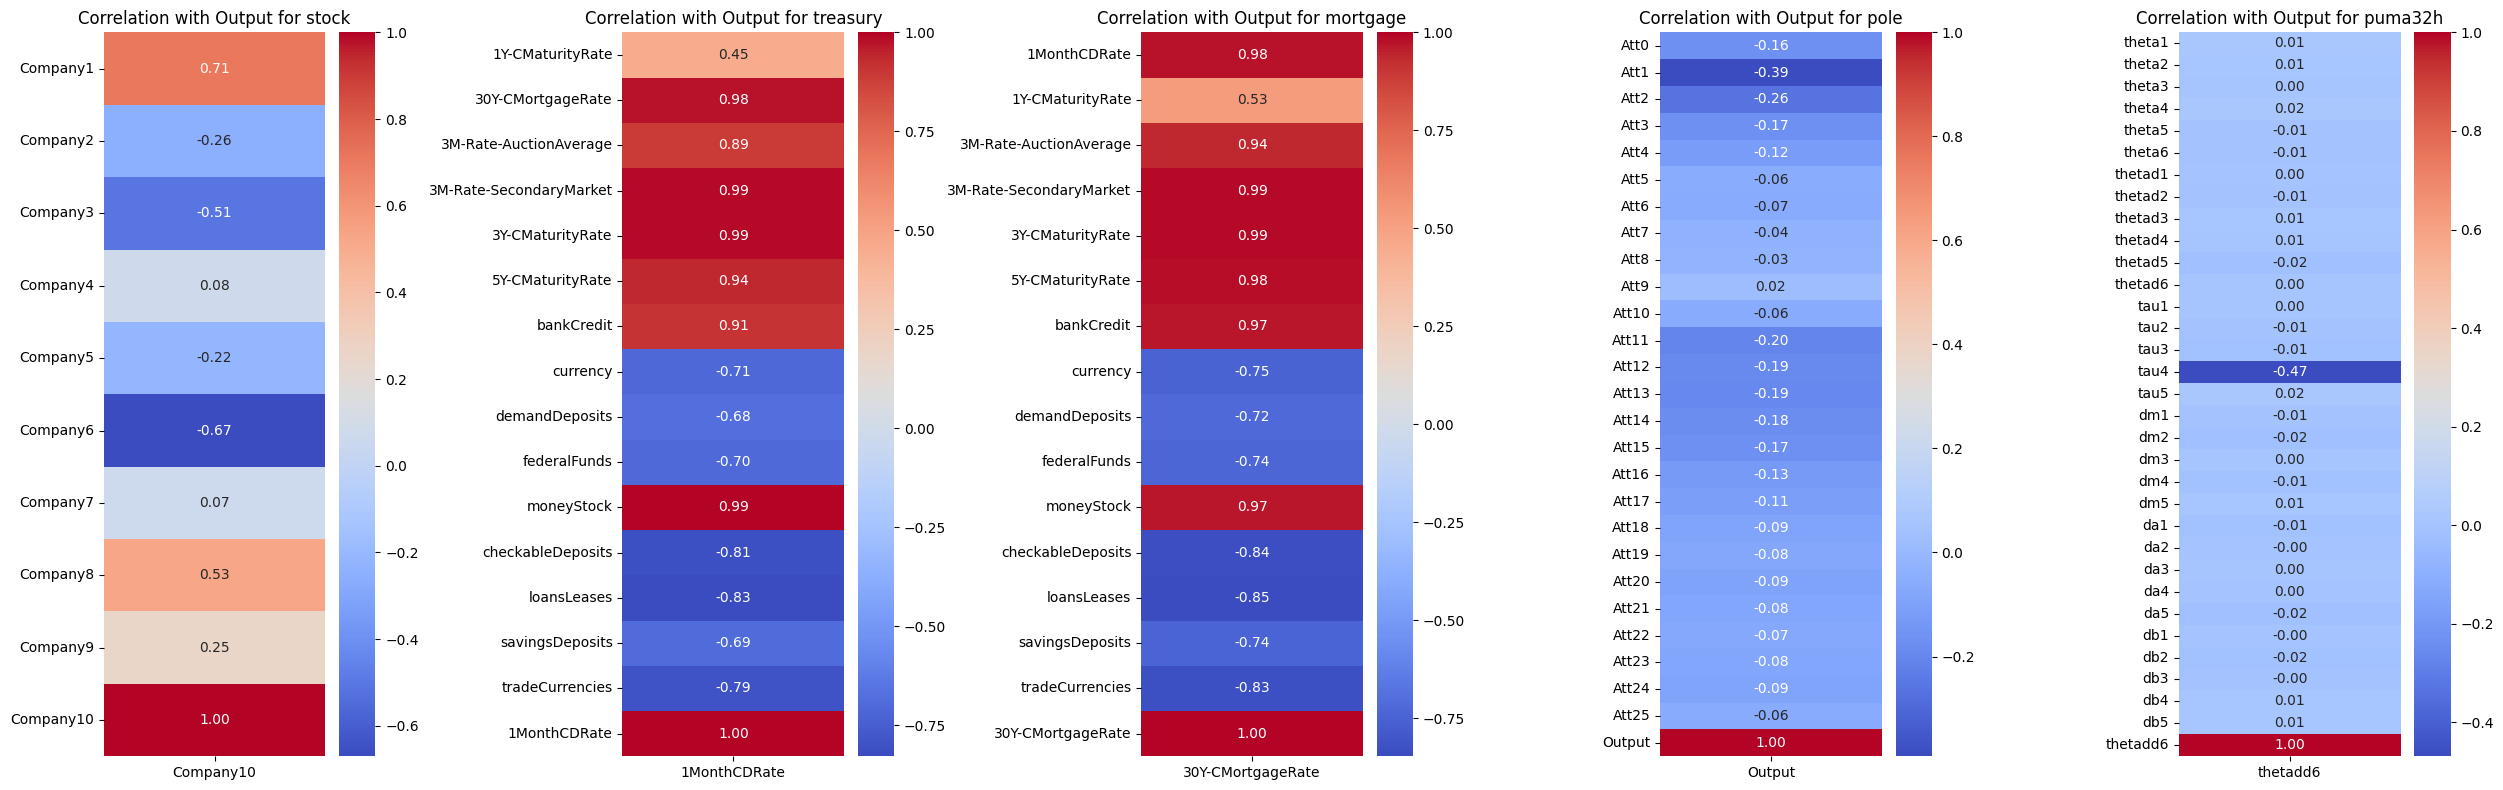

In [469]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 8))
for i, (name, data) in enumerate(DATASETS.items()):
    sns.heatmap(data['df'].corr()[[data['output']]], annot=True, cmap='coolwarm', fmt=".2f", ax=axes[i])
    axes[i].set_title(f'Correlation with Output for {name}')
plt.tight_layout()
plt.show()

# Implementacja Modelu Lasu Losowego

In [470]:
@dataclass(slots=True, init=False)
class TreeRegressorNode:
    max_depth: int
    min_samples_split: int
    left: Optional["TreeRegressorNode"]
    right: Optional["TreeRegressorNode"]
    feature_index: Optional[int]
    threshold: Optional[float]
    value: Optional[float]
    values: Optional[np.ndarray]

    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.left = None
        self.right = None
        self.feature_index = None
        self.threshold = None
        self.value = None
        self.values = None

    def __str__(self):
        return self._get_repr()

    @property
    def is_leaf(self) -> bool:
        return self.left is None and self.right is None

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        self._build_tree(X, y)

    def _build_tree(self, X: np.ndarray, y: np.ndarray, depth=0) -> None:
        if depth >= self.max_depth or len(X) < self.min_samples_split:
            self.value = np.mean(y)
            self.values = y
            return
        best_stddev = float('inf')
        _, n_features = X.shape
        features_to_check = np.random.choice(n_features, int(np.sqrt(n_features)), replace=False)
        for feature_index in features_to_check:
            thresholds = np.unique(X[:, feature_index])
            for threshold in thresholds:
                left_indices = X[:, feature_index] <= threshold
                right_indices = X[:, feature_index] > threshold
                if len(y[left_indices]) == 0 or len(y[right_indices]) == 0:
                    continue
                stddev_left = np.std(y[left_indices]) * len(y[left_indices]) / len(y)
                stddev_right = np.std(y[right_indices]) * len(y[right_indices]) / len(y)
                stddev = stddev_left + stddev_right
                if stddev < best_stddev:
                    best_stddev = stddev
                    self.feature_index = feature_index
                    self.threshold = threshold
        if self.feature_index is None:
            self.value = np.mean(y)
            self.values = y
            return
        X_left = X[X[:, self.feature_index] <= self.threshold]
        y_left = y[X[:, self.feature_index] <= self.threshold]
        self.left = TreeRegressorNode(self.max_depth, self.min_samples_split)
        self.left._build_tree(X_left, y_left, depth + 1)

        X_right = X[X[:, self.feature_index] > self.threshold]
        y_right = y[X[:, self.feature_index] > self.threshold]
        self.right = TreeRegressorNode(self.max_depth, self.min_samples_split)
        self.right._build_tree(X_right, y_right, depth + 1)

    def predict(self, X: np.ndarray) -> np.ndarray:
        if self.is_leaf:
            return np.full(X.shape[0], self.value)
        left_indices = X[:, self.feature_index] <= self.threshold
        right_indices = X[:, self.feature_index] > self.threshold
        predictions = np.empty(X.shape[0])
        predictions[left_indices] = self.left.predict(X[left_indices])
        predictions[right_indices] = self.right.predict(X[right_indices])
        return predictions

    def _get_repr(self, level=0) -> str:
        indent = "  " * level
        if self.is_leaf:
            return f"{indent}Leaf(value={self.value}, samples={len(self.values)})\n"
        else:
            repr = f"{indent}Node(feature_index={self.feature_index}, threshold={self.threshold})\n"
            return repr + self.left._get_repr(level + 1) + self.right._get_repr(level + 1)


In [471]:
@dataclass(slots=True)
class RandomForestRegressor:
    n_estimators: int
    max_depth: int
    min_samples_split: int
    roots: list[TreeRegressorNode]

    def __init__(self, n_estimators=100, max_depth=5, min_samples_split=2):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.roots = []

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        for i in range(self.n_estimators):
            print(f"Tree: {i + 1}/{self.n_estimators}", end='\r')
            indices = np.random.choice(X.shape[0], X.shape[0])
            X_sample = X[indices]
            y_sample = y[indices]
            root = TreeRegressorNode(max_depth=self.max_depth, min_samples_split=self.min_samples_split)
            root.fit(X_sample, y_sample)
            self.roots.append(root)

    def predict(self, X: np.ndarray) -> np.ndarray:
        predictions = np.array([root.predict(X) for root in self.roots])
        return np.mean(predictions, axis=0)

    def get_sparse_data_repr(self, X: np.ndarray) -> np.ndarray:
        return np.array([root.predict(X) for root in self.roots]).transpose()


# Trenowanie modeli

In [472]:
train_models = False
if train_models:
    TRAINED_MODELS = {}
    for set_name, data in DATASETS.items():
        print(f"Set: {set_name}")
        regressor = RandomForestRegressor(n_estimators=100, max_depth=30, min_samples_split=2)
        regressor.fit(DATASETS[set_name]['X_train'].values, DATASETS[set_name]['y_train'].values)
        TRAINED_MODELS[set_name] = regressor

    for set_name, regressor in TRAINED_MODELS.items():
        model_path = Path("models").joinpath(f"{set_name}_random_forest.pkl")
        os.makedirs(model_path.parent, exist_ok=True)
        with open(model_path, "wb") as f:
            pickle.dump(regressor, f)

In [473]:
RESULTS = {set_name: {} for set_name in DATASETS.keys()}

# Predykcje standardowego algorytmu lasu losowego

In [474]:
def load_model(set_name: str) -> RandomForestRegressor:
    model_path = Path("models").joinpath(f"{set_name}_random_forest.pkl")
    with open(model_path, "rb") as f:
        return pickle.load(f)

for set_name in DATASETS.keys():
    regressor = load_model(set_name)
    DATASETS[set_name]['regressor'] = regressor

In [475]:
print(DATASETS['puma32h']['regressor'].roots[0])

Node(feature_index=15, threshold=-15.773017)
  Node(feature_index=2, threshold=2.338787)
    Node(feature_index=20, threshold=1.065971)
      Node(feature_index=14, threshold=-3.297555)
        Node(feature_index=15, threshold=-43.875792)
          Node(feature_index=24, threshold=0.387001)
            Node(feature_index=1, threshold=-2.12051)
              Leaf(value=0.010557, samples=1)
              Node(feature_index=20, threshold=0.266928)
                Node(feature_index=1, threshold=-0.388783)
                  Leaf(value=0.041607, samples=2)
                  Leaf(value=0.05295, samples=2)
                Node(feature_index=24, threshold=0.307437)
                  Node(feature_index=15, threshold=-74.204906)
                    Leaf(value=0.083206, samples=3)
                    Node(feature_index=3, threshold=-0.02552)
                      Leaf(value=0.075028, samples=3)
                      Leaf(value=0.072171, samples=3)
                  Node(feature_index=26, threshol

In [476]:
def calc_mse(set_name: str, preds: np.ndarray, train: bool = True) -> float:
    subset = 'y_train' if train else 'y_test'
    return np.mean((preds - DATASETS[set_name][subset].values) ** 2)

In [477]:
for set_name in DATASETS.keys():
    print(f"SET: {set_name}")
    random_forest_train_preds = DATASETS[set_name]['regressor'].predict(DATASETS[set_name]['X_train'].values)
    train_mse = mean_squared_error(DATASETS[set_name]['y_train'].values, random_forest_train_preds)
    train_r2 = r2_score(DATASETS[set_name]['y_train'].values, random_forest_train_preds)
    print(f"\tTRAIN MSE for {set_name}: {train_mse:.6f}")
    print(f"\tTRAIN R2 for {set_name}: {train_r2:.6f}")
    random_forest_test_preds = DATASETS[set_name]['regressor'].predict(DATASETS[set_name]['X_test'].values)
    test_mse = mean_squared_error(DATASETS[set_name]['y_test'].values, random_forest_test_preds)
    test_r2 = r2_score(DATASETS[set_name]['y_test'].values, random_forest_test_preds)
    print(f"\tTEST MSE for {set_name}: {test_mse:.6f}")
    print(f"\tTEST R2 for {set_name}: {test_r2:.6f}")

    RESULTS[set_name]['random_forest'] = {
        'train_preds': random_forest_train_preds,
        'train_mse': train_mse,
        'train_r2': train_r2,
        'test_preds': random_forest_test_preds,
        'test_mse': test_mse,
        'test_r2': test_r2,
    }

SET: stock
	TRAIN MSE for stock: 0.091499
	TRAIN R2 for stock: 0.997938
	TEST MSE for stock: 0.713924
	TEST R2 for stock: 0.980197
SET: treasury
	TRAIN MSE for treasury: 0.006480
	TRAIN R2 for treasury: 0.999431
	TEST MSE for treasury: 0.109715
	TEST R2 for treasury: 0.990295
SET: mortgage
	TRAIN MSE for mortgage: 0.003821
	TRAIN R2 for mortgage: 0.999604
	TEST MSE for mortgage: 0.038549
	TEST R2 for mortgage: 0.995979
SET: pole
	TRAIN MSE for pole: 8.468443
	TRAIN R2 for pole: 0.995084
	TEST MSE for pole: 28.003398
	TEST R2 for pole: 0.984536
SET: puma32h
	TRAIN MSE for puma32h: 0.000038
	TRAIN R2 for puma32h: 0.959311
	TEST MSE for puma32h: 0.000241
	TEST R2 for puma32h: 0.721040


# Rzadka reprezentacja danych

In [478]:
for set_name in DATASETS.keys():
    regressor = DATASETS[set_name]['regressor']
    DATASETS[set_name]['sparse_repr_train'] = regressor.get_sparse_data_repr(DATASETS[set_name]['X_train'].values)
    DATASETS[set_name]['sparse_repr_test'] = regressor.get_sparse_data_repr(DATASETS[set_name]['X_test'].values)

# Model regresji liniowej wytrenowany na rzadkiej reprezentacji danych

In [479]:
for set_name in DATASETS.keys():
    linear_model_sparse = LinearRegression()
    linear_model_sparse.fit(DATASETS[set_name]['sparse_repr_train'], DATASETS[set_name]['y_train'].values)
    DATASETS[set_name]['linear_model_sparse'] = linear_model_sparse

In [480]:
for set_name in DATASETS.keys():
    linear_model_sparse = DATASETS[set_name]['linear_model_sparse']
    sparse_repr_train = DATASETS[set_name]['sparse_repr_train']
    sparse_repr_test = DATASETS[set_name]['sparse_repr_test']
    linear_model_sparse_train_preds = linear_model_sparse.predict(sparse_repr_train)
    linear_model_sparse_test_preds = linear_model_sparse.predict(sparse_repr_test)
    print(f"SET: {set_name}")
    train_mse_sparse = mean_squared_error(DATASETS[set_name]['y_train'].values, linear_model_sparse_train_preds)
    train_r2_sparse = r2_score(DATASETS[set_name]['y_train'].values, linear_model_sparse_train_preds)
    print(f"\tTRAIN MSE: {train_mse_sparse:.6f}")
    print(f"\tTRAIN R2: {train_r2_sparse:.6f}")
    test_mse_sparse = mean_squared_error(DATASETS[set_name]['y_test'].values, linear_model_sparse_test_preds)
    test_r2_sparse = r2_score(DATASETS[set_name]['y_test'].values, linear_model_sparse_test_preds)
    print(f"\tTEST MSE: {test_mse_sparse:.6f}")
    print(f"\tTEST R2: {test_r2_sparse:.6f}")

    RESULTS[set_name]['sparse_linear'] = {
        'train_preds': linear_model_sparse_train_preds,
        'train_mse': train_mse_sparse,
        'train_r2': train_r2_sparse,
        'test_preds': linear_model_sparse_test_preds,
        'test_mse': test_mse_sparse,
        'test_r2': test_r2_sparse,
    }


SET: stock
	TRAIN MSE: 0.059728
	TRAIN R2: 0.998654
	TEST MSE: 0.671553
	TEST R2: 0.981372
SET: treasury
	TRAIN MSE: 0.003023
	TRAIN R2: 0.999734
	TEST MSE: 0.108544
	TEST R2: 0.990398
SET: mortgage
	TRAIN MSE: 0.001595
	TRAIN R2: 0.999835
	TEST MSE: 0.024722
	TEST R2: 0.997421
SET: pole
	TRAIN MSE: 5.003269
	TRAIN R2: 0.997096
	TEST MSE: 22.563980
	TEST R2: 0.987540
SET: puma32h
	TRAIN MSE: 0.000011
	TRAIN R2: 0.987663
	TEST MSE: 0.000159
	TEST R2: 0.815565


# Model regresji liniowej wytrenowany na oryginalnych danych

In [481]:
for set_name in DATASETS.keys():
    linear_model = LinearRegression()
    linear_model.fit(DATASETS[set_name]['X_train'].values, DATASETS[set_name]['y_train'].values)
    DATASETS[set_name]['linear_model'] = linear_model

In [482]:
for set_name in DATASETS.keys():
    linear_model = DATASETS[set_name]['linear_model']
    linear_model_preds_train = linear_model.predict(DATASETS[set_name]['X_train'].values)
    print(f"SET: {set_name}")
    train_mse = mean_squared_error(DATASETS[set_name]['y_train'].values, linear_model_preds_train)
    train_r2 = r2_score(DATASETS[set_name]['y_train'].values, linear_model_preds_train)
    print(f"\tTRAIN MSE: {train_mse:.6f}")
    print(f"\tTRAIN R2: {train_r2:.6f}")
    linear_model_preds_test = linear_model.predict(DATASETS[set_name]['X_test'].values)
    test_mse = mean_squared_error(DATASETS[set_name]['y_test'].values, linear_model_preds_test)
    test_r2 = r2_score(DATASETS[set_name]['y_test'].values, linear_model_preds_test)
    print(f"\tTEST MSE: {test_mse:.6f}")
    print(f"\tTEST R2: {test_r2:.6f}")

    RESULTS[set_name]['linear'] = {
        'train_preds': linear_model_preds_train,
        'train_mse': train_mse,
        'train_r2': train_r2,
        'test_preds': linear_model_preds_test,
        'test_mse': test_mse,
        'test_r2': test_r2,
    }

SET: stock
	TRAIN MSE: 5.354823
	TRAIN R2: 0.879325
	TEST MSE: 5.562569
	TEST R2: 0.845703
SET: treasury
	TRAIN MSE: 0.050175
	TRAIN R2: 0.995591
	TEST MSE: 0.079880
	TEST R2: 0.992934
SET: mortgage
	TRAIN MSE: 0.012942
	TRAIN R2: 0.998659
	TEST MSE: 0.017260
	TEST R2: 0.998200
SET: pole
	TRAIN MSE: 926.445679
	TRAIN R2: 0.462192
	TEST MSE: 930.429576
	TEST R2: 0.486214
SET: puma32h
	TRAIN MSE: 0.000721
	TRAIN R2: 0.222690
	TEST MSE: 0.000677
	TEST R2: 0.216123


# Prezentacja wyników

## Wykresy i historgramy wartości prawdziwych i przewidzianych przez poszczególne modele


============================ RESULTS FOR SET: STOCK ============================



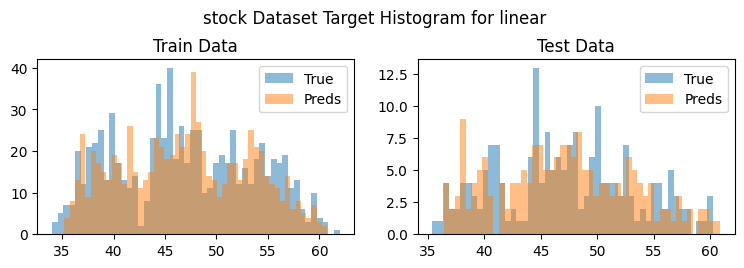

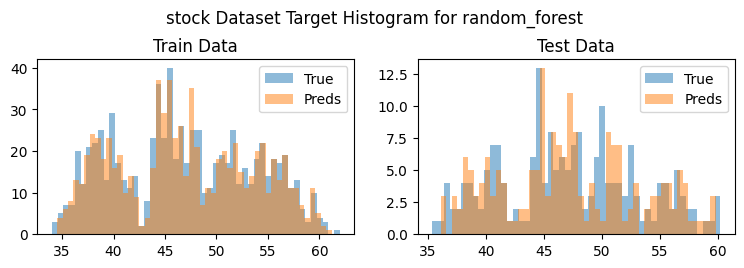

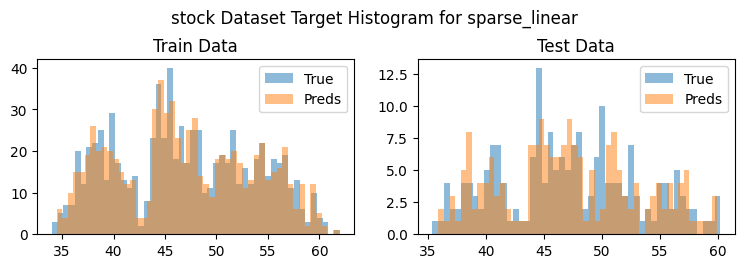

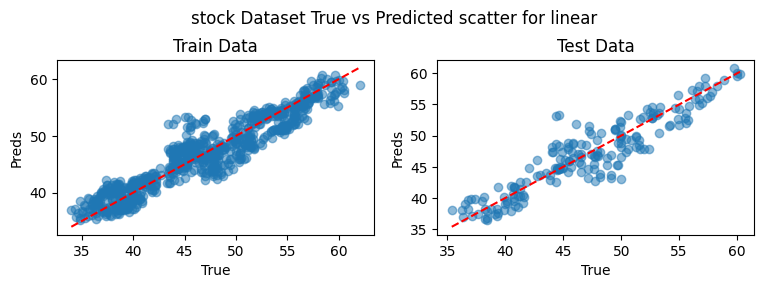

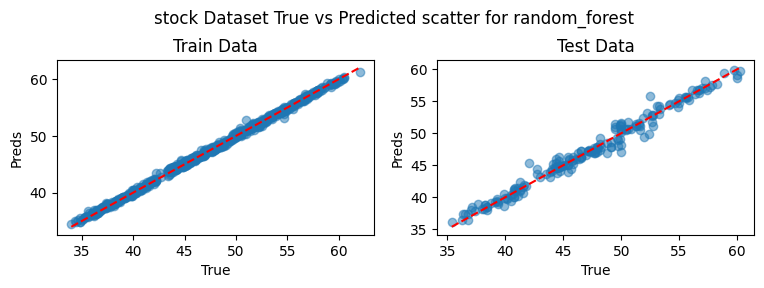

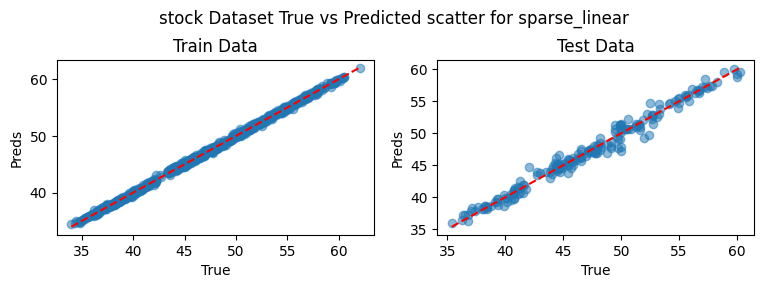

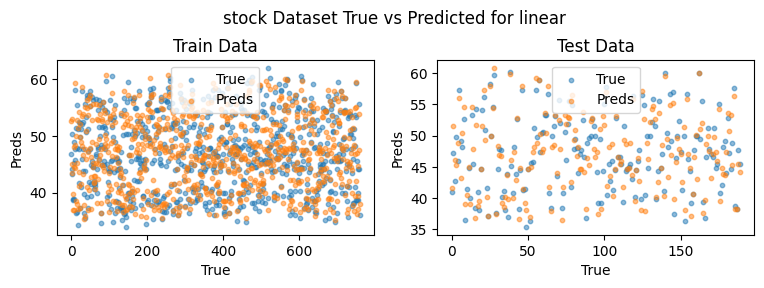

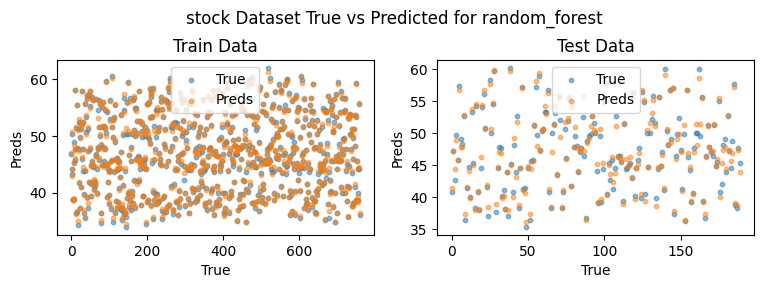

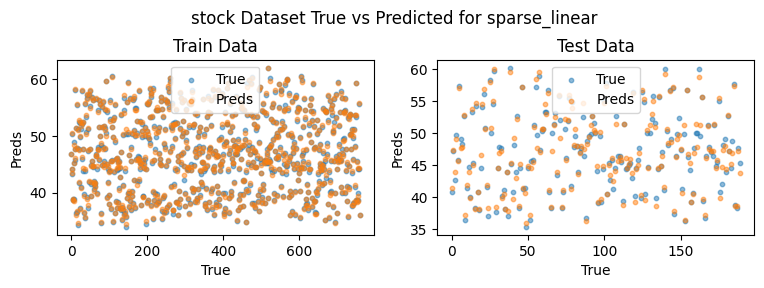


========================== RESULTS FOR SET: TREASURY ===========================



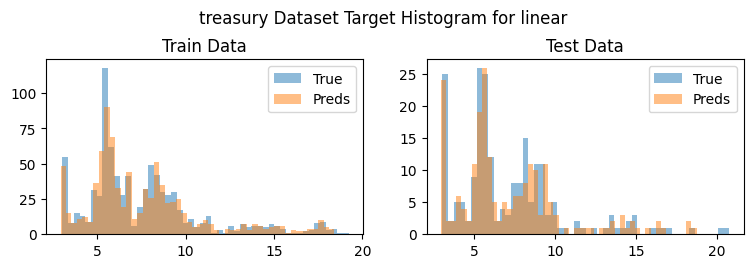

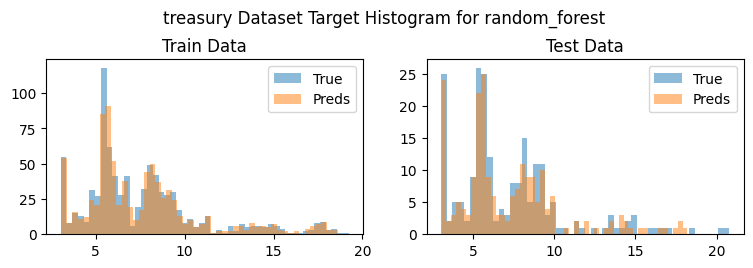

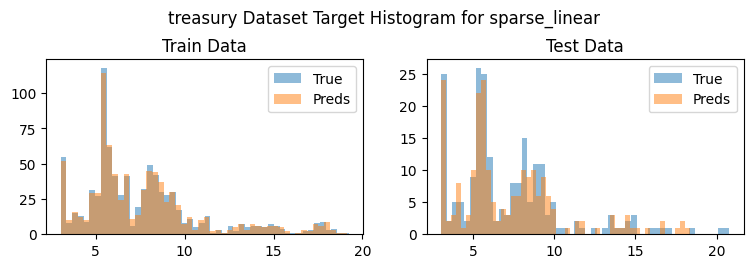

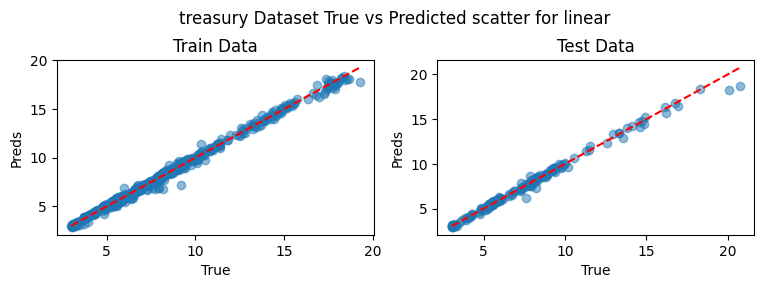

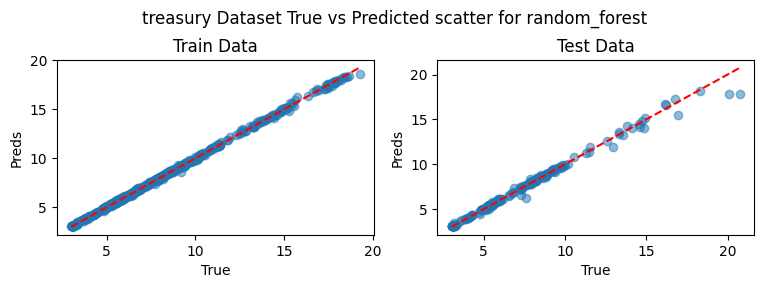

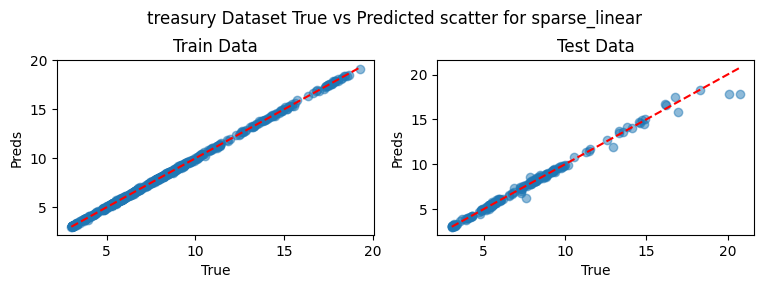

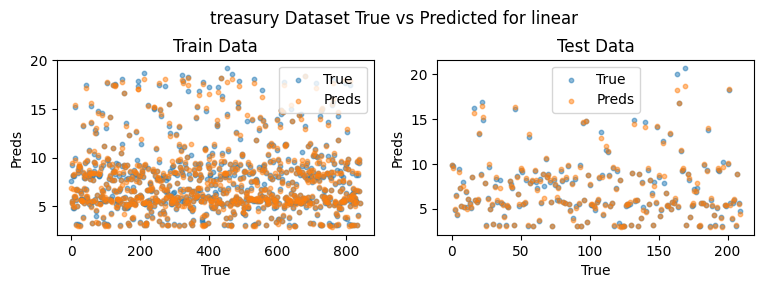

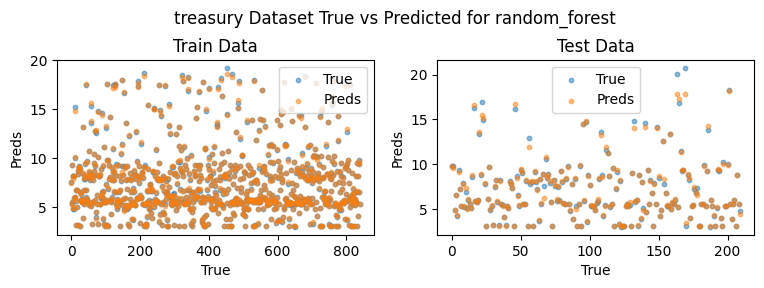

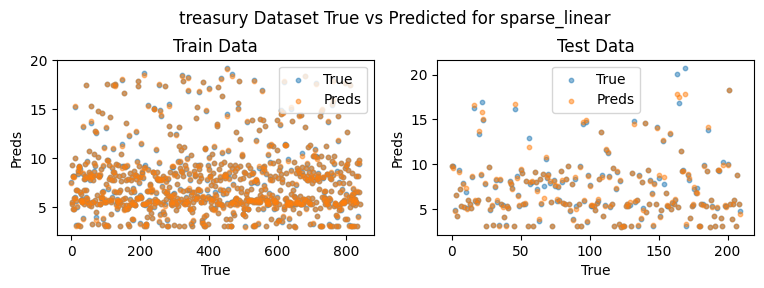


========================== RESULTS FOR SET: MORTGAGE ===========================



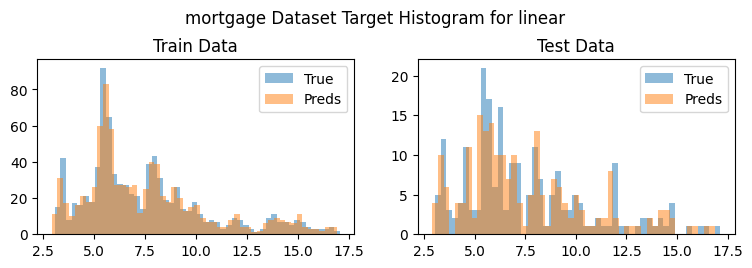

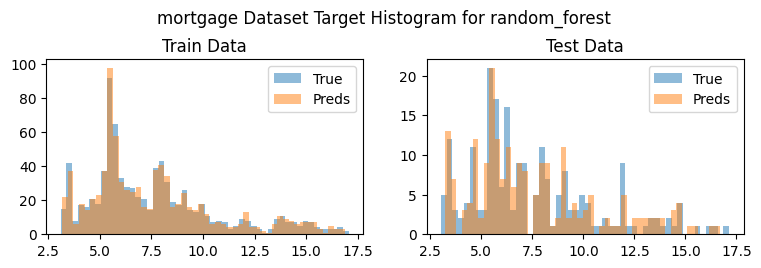

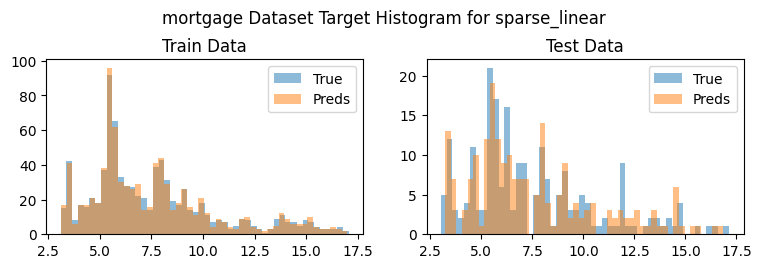

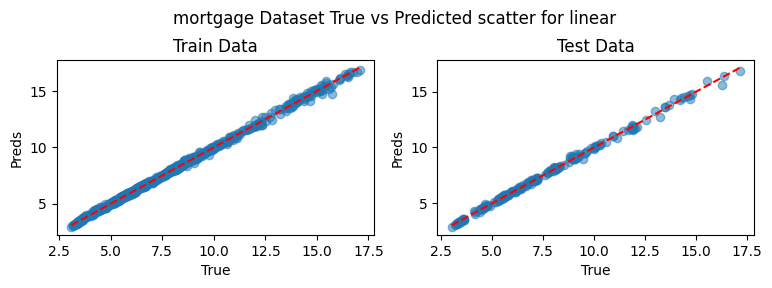

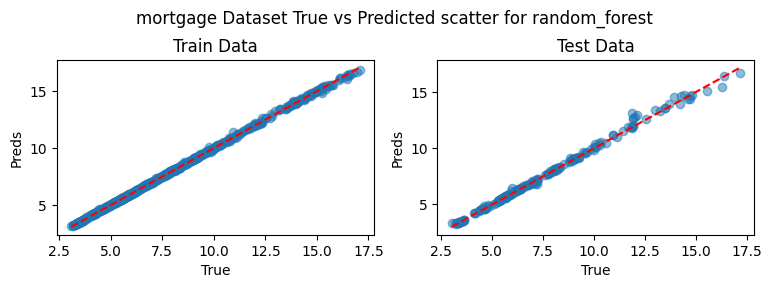

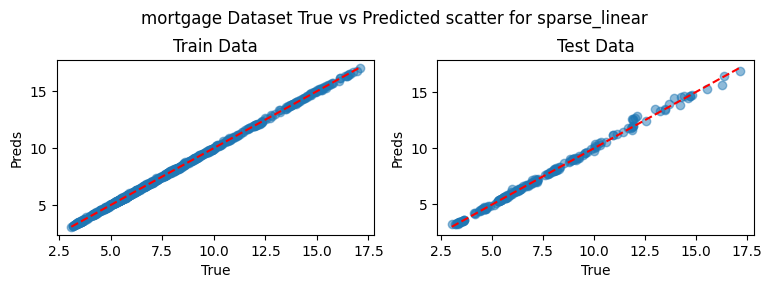

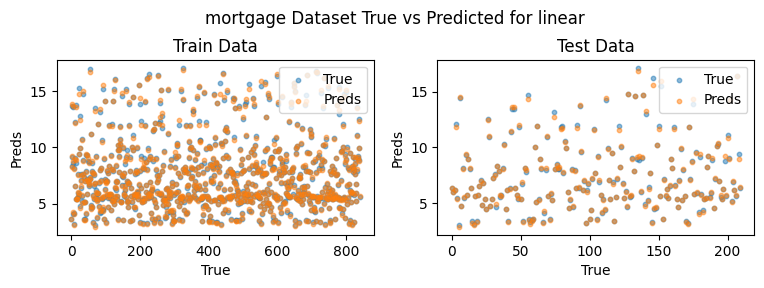

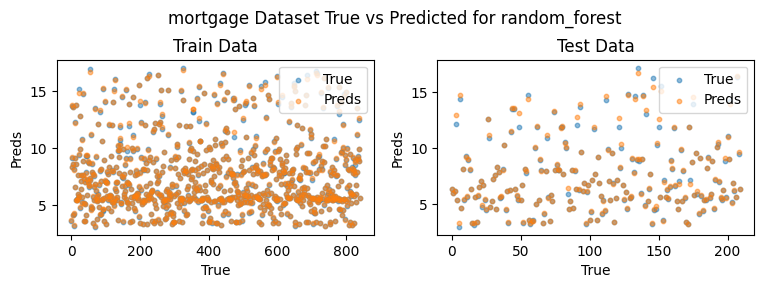

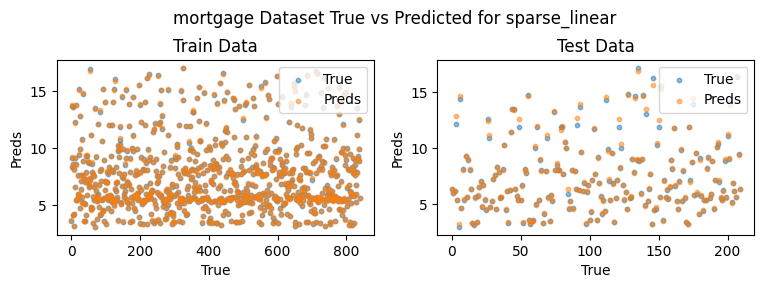


============================ RESULTS FOR SET: POLE =============================



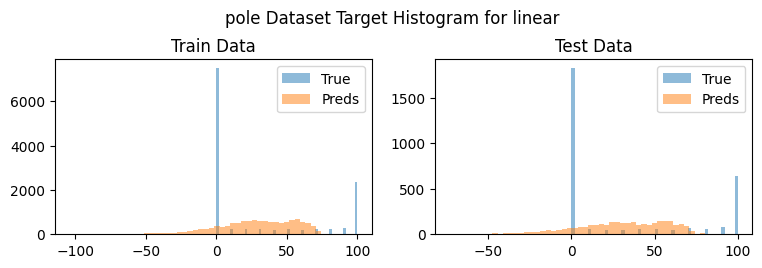

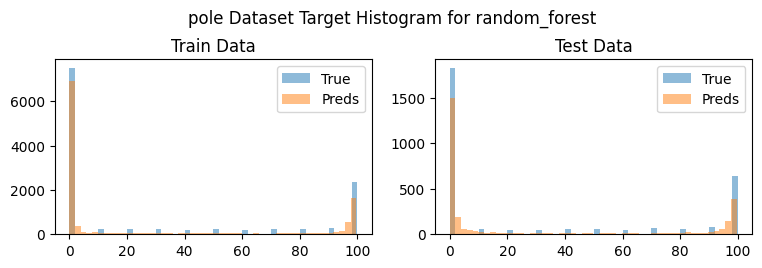

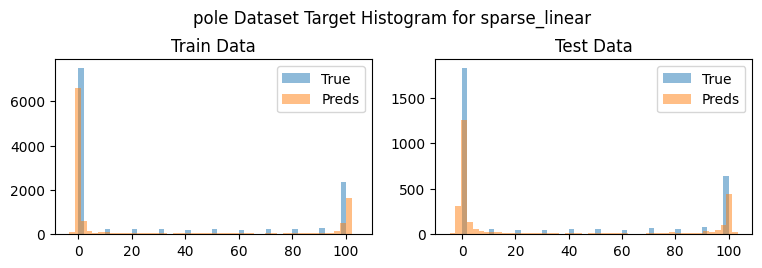

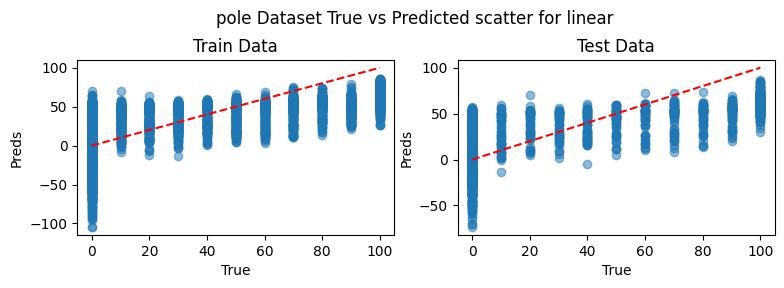

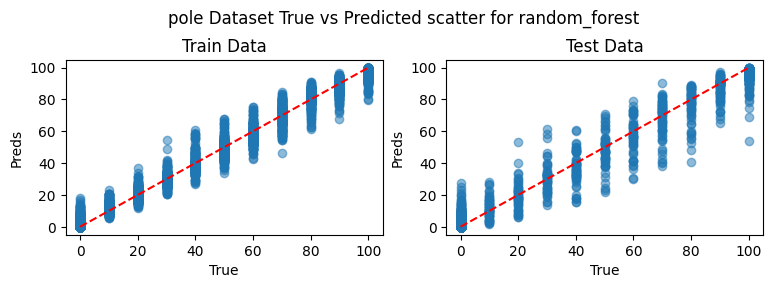

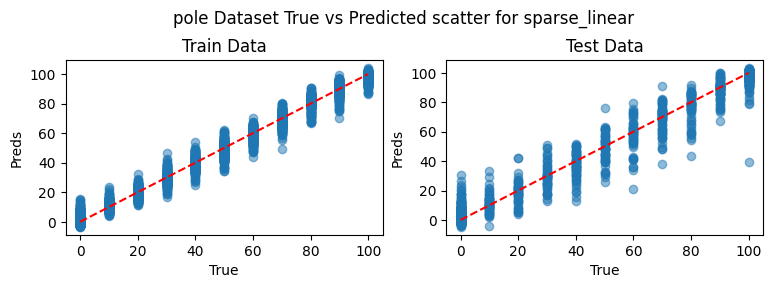

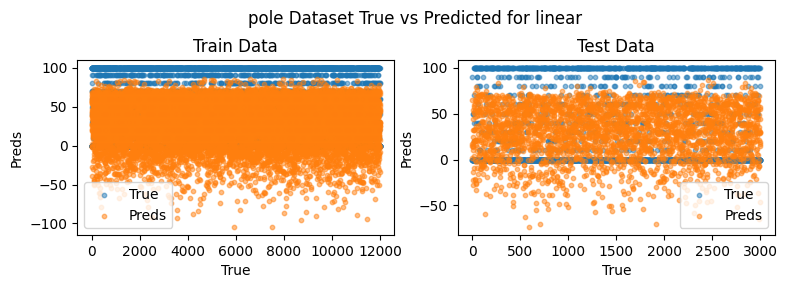

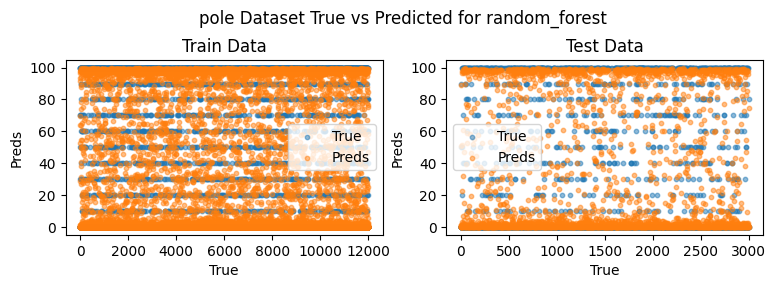

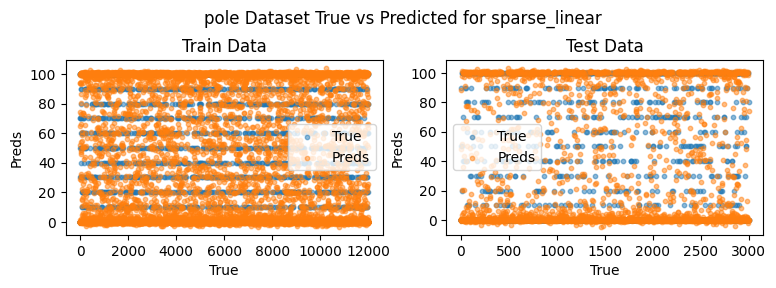


=========================== RESULTS FOR SET: PUMA32H ===========================



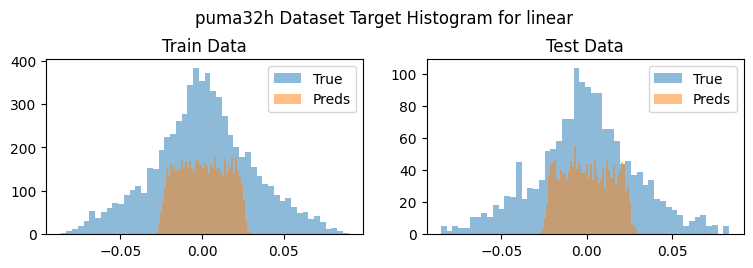

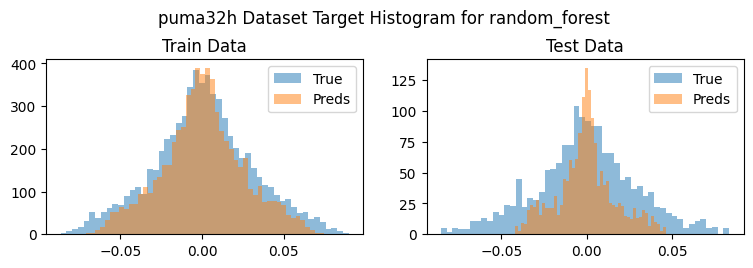

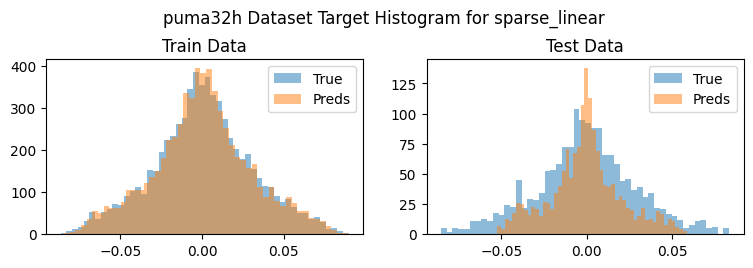

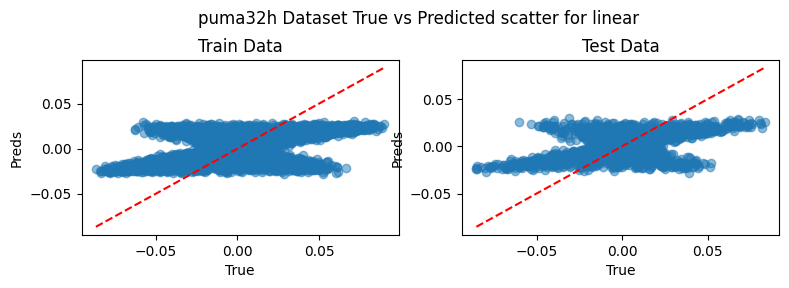

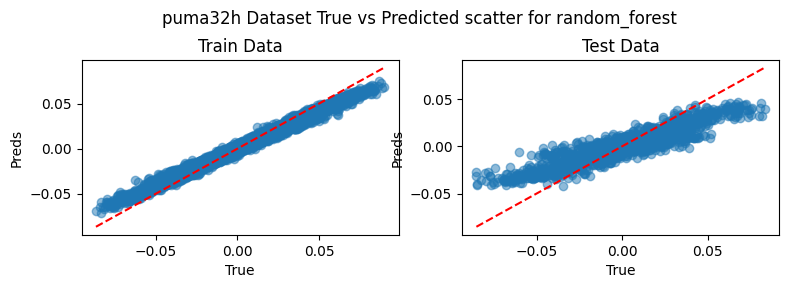

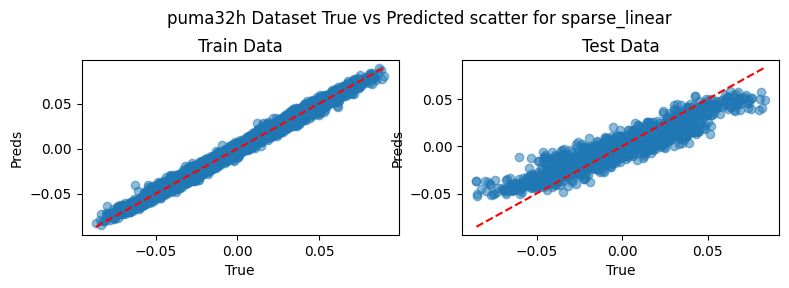

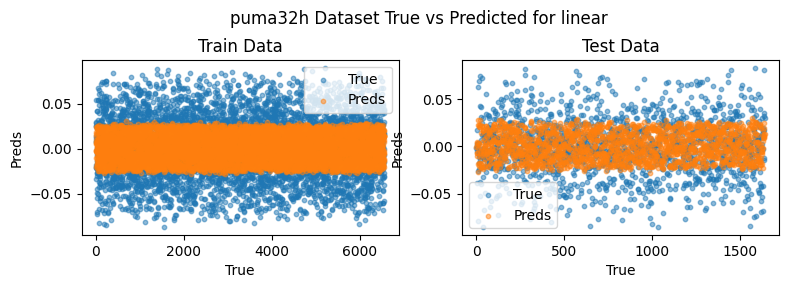

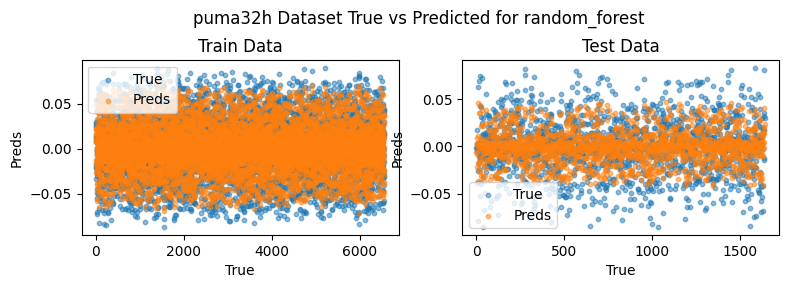

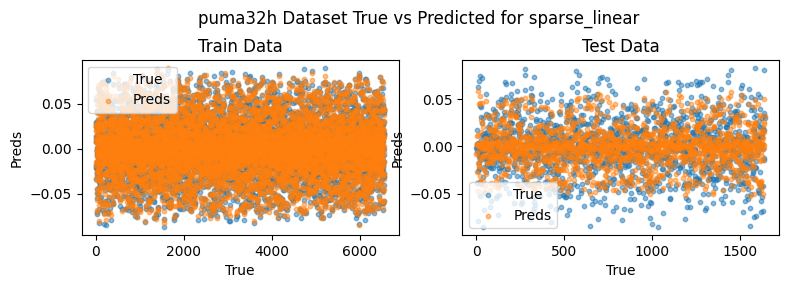

In [483]:
subplots_rows = 2
subplots_cols = 2
figsize = (9, 5)
models = ['linear', 'random_forest', 'sparse_linear']

for set_name in DATASETS.keys():
    print("\n" + "=" * 80)
    print(f" RESULTS FOR SET: {set_name.upper()} ".center(80, "="))
    print("=" * 80 + "\n")
    for model_name in models:
        # ****************************
        #         HISTOGRAM
        # ****************************
        plt.figure(figsize=figsize)
        plt.suptitle(f'{set_name} Dataset Target Histogram for {model_name}')

        plt.subplot(subplots_rows, subplots_cols, 1)
        plt.hist(DATASETS[set_name]['y_train'], bins=50, alpha=0.5, label='True')
        plt.hist(RESULTS[set_name][model_name]['train_preds'], bins=50, alpha=0.5, label='Preds')
        plt.title('Train Data')
        plt.legend()

        plt.subplot(subplots_rows, subplots_cols, 2)
        plt.hist(DATASETS[set_name]['y_test'], bins=50, alpha=0.5, label='True')
        plt.hist(RESULTS[set_name][model_name]['test_preds'], bins=50, alpha=0.5, label='Preds')
        plt.title('Test Data')
        plt.legend()

        plt.show()

    for model_name in models:
        # ****************************
        #      Target vs predicted scatter
        # ****************************
        plt.figure(figsize=figsize)
        plt.suptitle(f'{set_name} Dataset True vs Predicted scatter for {model_name}')

        plt.subplot(subplots_rows, subplots_cols, 1)
        y_pred = RESULTS[set_name][model_name]['train_preds']
        y_true = DATASETS[set_name]['y_train'].values
        plt.scatter(y_true, y_pred, alpha=0.5)
        plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
        plt.title('Train Data')
        plt.xlabel('True')
        plt.ylabel('Preds')

        plt.subplot(subplots_rows, subplots_cols, 2)
        y_pred = RESULTS[set_name][model_name]['test_preds']
        y_true = DATASETS[set_name]['y_test'].values
        plt.scatter(y_true, y_pred, alpha=0.5)
        plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
        plt.title('Test Data')
        plt.xlabel('True')
        plt.ylabel('Preds')

        plt.show()

    for model_name in models:
        # ****************************
        #      Target vs predicted
        # ****************************
        plt.figure(figsize=figsize)
        plt.suptitle(f'{set_name} Dataset True vs Predicted for {model_name}')

        plt.subplot(subplots_rows, subplots_cols, 1)
        y_pred = RESULTS[set_name][model_name]['train_preds']
        y_true = DATASETS[set_name]['y_train'].values
        x = np.arange(len(y_true))
        plt.scatter(x, y_true, label='True', alpha=0.5, s=10)
        plt.scatter(x, y_pred, label='Preds', alpha=0.5, s=10)
        plt.title('Train Data')
        plt.xlabel('True')
        plt.ylabel('Preds')
        plt.legend()

        plt.subplot(subplots_rows, subplots_cols, 2)
        y_pred = RESULTS[set_name][model_name]['test_preds']
        y_true = DATASETS[set_name]['y_test'].values
        x = np.arange(len(y_true))
        plt.scatter(x, y_true, label='True', alpha=0.5, s=10)
        plt.scatter(x, y_pred, label='Preds', alpha=0.5, s=10)
        plt.title('Test Data')
        plt.xlabel('True')
        plt.ylabel('Preds')
        plt.legend()

        plt.show()

## Błędy średniokwadratowe na poszczególnych zbiorach

In [484]:
from prettytable import PrettyTable

table = PrettyTable()
table.field_names = ["Dataset", "Model", "Train MSE", "Test MSE", "Train R2", "Test R2"]
for set_name in DATASETS.keys():
    for model_name in models:
        train_mse = RESULTS[set_name][model_name]['train_mse']
        test_mse = RESULTS[set_name][model_name]['test_mse']
        train_r2 = RESULTS[set_name][model_name]['train_r2']
        test_r2 = RESULTS[set_name][model_name]['test_r2']
        table.add_row([set_name, model_name, f"{train_mse:.6f}", f"{test_mse:.6f}", f"{train_r2:.6f}", f"{test_r2:.6f}"])
print(table)

+----------+---------------+------------+------------+----------+----------+
| Dataset  |     Model     | Train MSE  |  Test MSE  | Train R2 | Test R2  |
+----------+---------------+------------+------------+----------+----------+
|  stock   |     linear    |  5.354823  |  5.562569  | 0.879325 | 0.845703 |
|  stock   | random_forest |  0.091499  |  0.713924  | 0.997938 | 0.980197 |
|  stock   | sparse_linear |  0.059728  |  0.671553  | 0.998654 | 0.981372 |
| treasury |     linear    |  0.050175  |  0.079880  | 0.995591 | 0.992934 |
| treasury | random_forest |  0.006480  |  0.109715  | 0.999431 | 0.990295 |
| treasury | sparse_linear |  0.003023  |  0.108544  | 0.999734 | 0.990398 |
| mortgage |     linear    |  0.012942  |  0.017260  | 0.998659 | 0.998200 |
| mortgage | random_forest |  0.003821  |  0.038549  | 0.999604 | 0.995979 |
| mortgage | sparse_linear |  0.001595  |  0.024722  | 0.999835 | 0.997421 |
|   pole   |     linear    | 926.445679 | 930.429576 | 0.462192 | 0.486214 |

# Analiza rzadkiej reprezentacji wygenerowanej przez model

## Korelacja liniowa cech wygenerowanych przez las losowy z funkcją celu

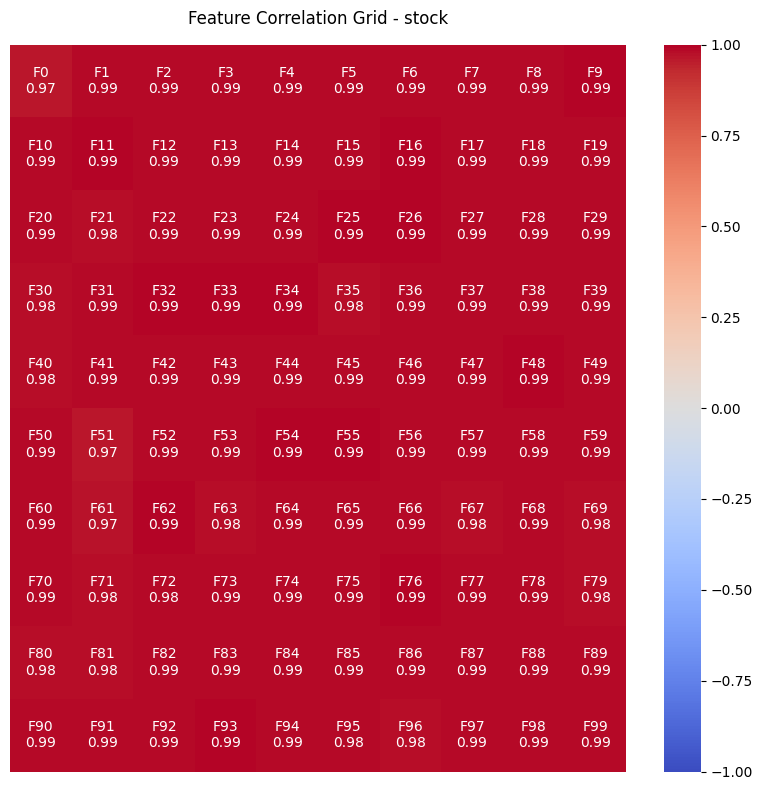

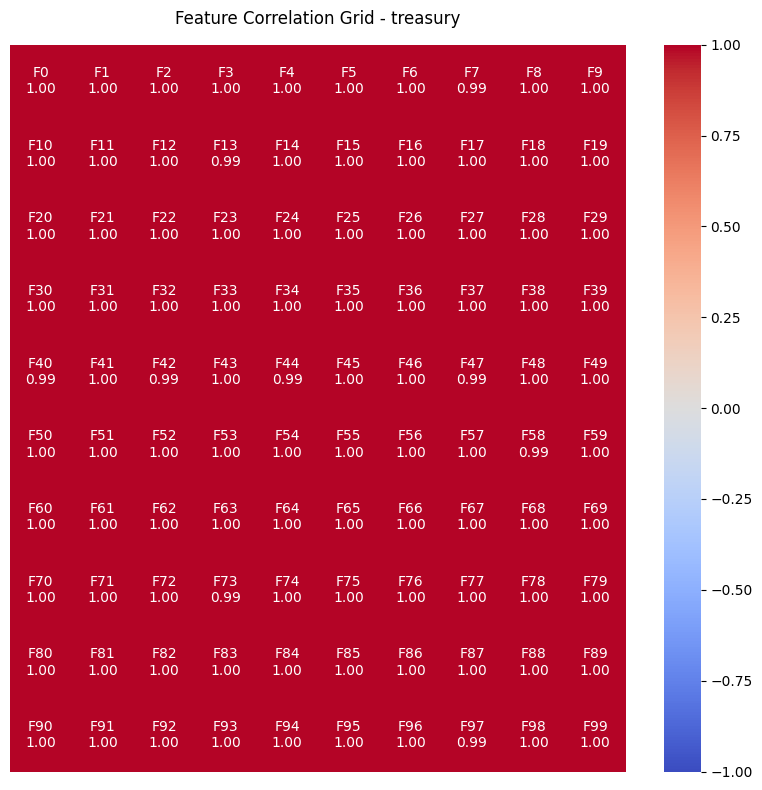

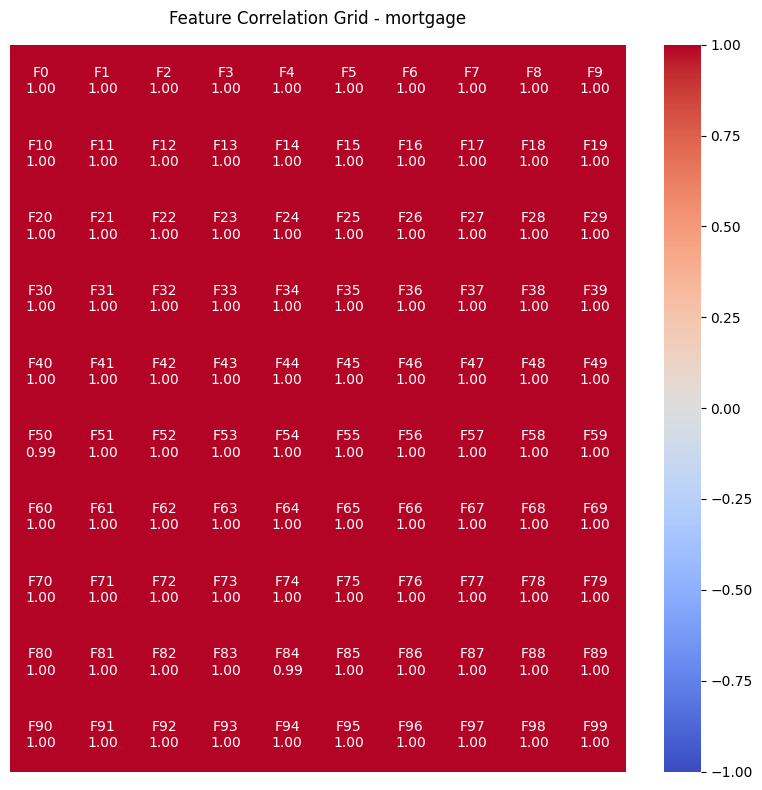

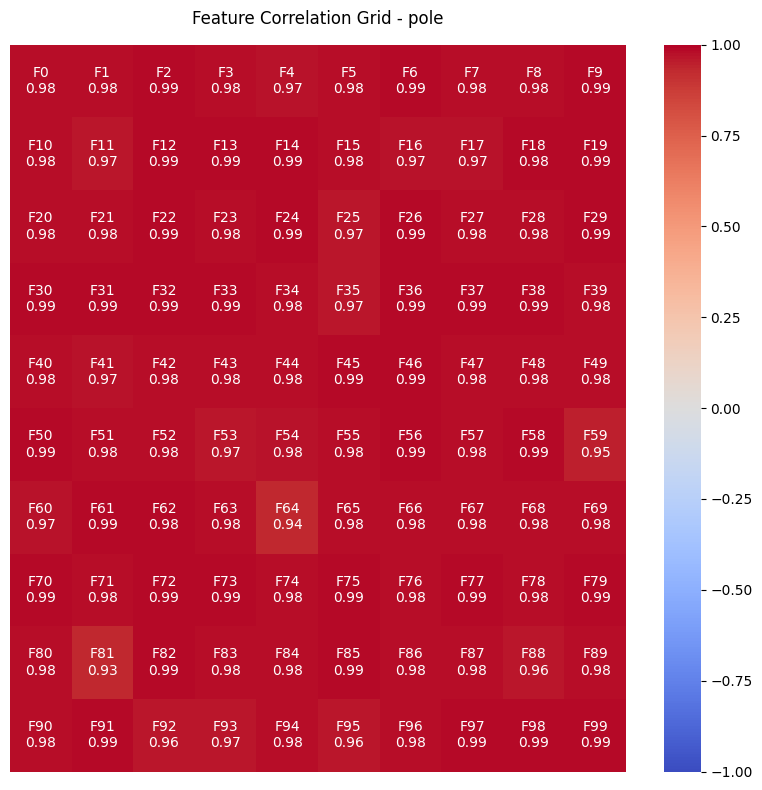

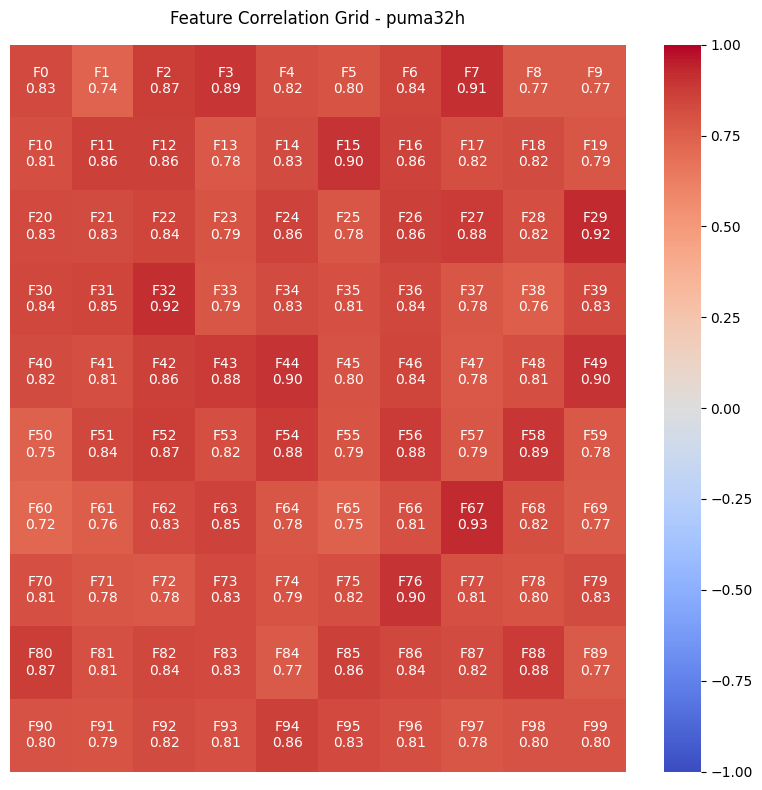

In [485]:
for set_name in DATASETS.keys():
    X = DATASETS[set_name]['sparse_repr_train']
    y = DATASETS[set_name]['y_train'].values

    n_features = X.shape[1]
    correlations = np.array([np.corrcoef(X[:, i], y)[0, 1] for i in range(n_features)])

    n_cols = 10
    n_rows = int(np.ceil(n_features / n_cols))

    padded_corrs = np.full(n_rows * n_cols, np.nan)
    padded_corrs[:n_features] = correlations
    grid_data = padded_corrs.reshape(n_rows, n_cols)

    labels = np.full(n_rows * n_cols, "", dtype=object)
    for i in range(n_features):
        labels[i] = f"F{i}\n{correlations[i]:.2f}"
    grid_labels = labels.reshape(n_rows, n_cols)

    plt.figure(figsize=(8, 8))
    sns.heatmap(
        grid_data,
        annot=grid_labels,
        fmt="",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        cbar=True,
        xticklabels=False,
        yticklabels=False
    )
    plt.title(f"Feature Correlation Grid - {set_name}", pad=15)
    plt.tight_layout()
    plt.show()